# 06 · Forecasting monthly obligations: SARIMA, SARIMAX and a rolling-origin backtest

**Series:** DOT contract obligations per calendar month, October 2011 - September 2026 (180 months).

The series has strong fiscal-year seasonality (September is about twice an average month because annual money
expires) and a few known shocks:
- **Government shutdowns** freeze new obligations: October 2013, late December 2018 - January 2019, and
  October - mid-November 2025.
- **The Infrastructure Investment and Jobs Act** (signed November 2021) raised DOT's funding from FY2022 on.

Plan: stationarity tests → SARIMA order selection on log obligations → SARIMAX with shutdown and IIJA regressors
→ residual diagnostics → rolling-origin backtest against a seasonal-naive baseline → FY2027 forecast.

In [1]:
import sys; sys.path.append("..")
import itertools
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss
from src.features import load_monthly

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
FIG = "../reports/figures/"
m = load_monthly().set_index("month").asfreq("MS")
y = np.log(m["obligations"])
print(f"{len(y)} months, {y.index.min():%Y-%m} to {y.index.max():%Y-%m}")

180 months, 2011-10 to 2026-09


## Decomposition and stationarity

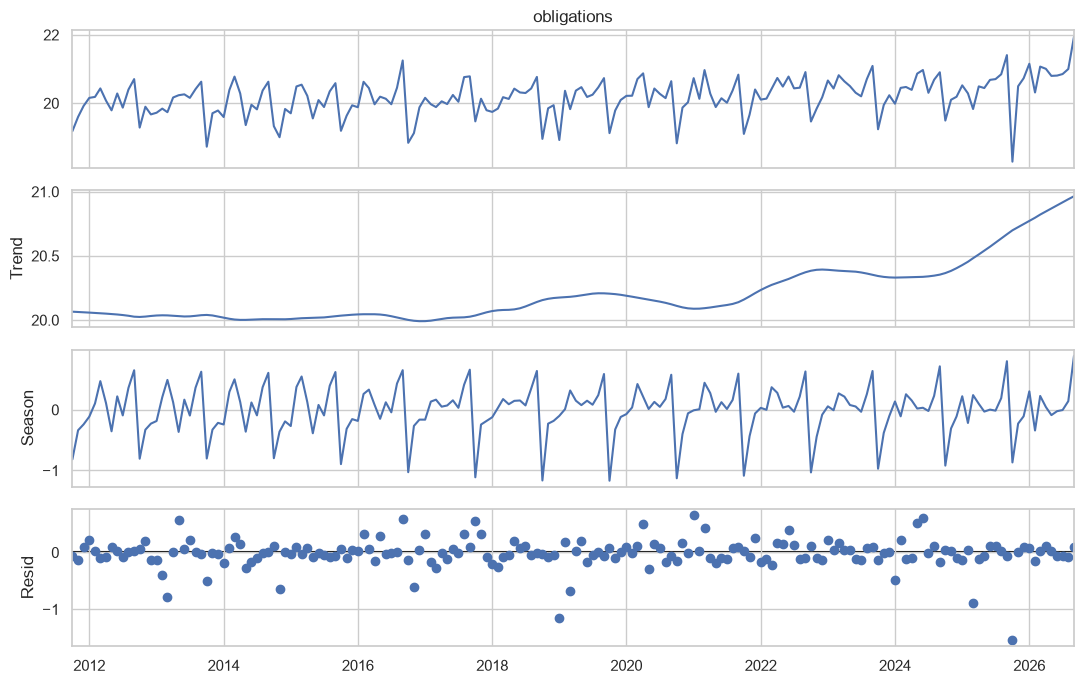

,ADF p (H0: unit root),KPSS p (H0: stationary)
series,,
log obligations,0.992,0.010
seasonal difference (lag 12),0.000,0.100
seasonal + first difference,0.000,0.062


In [2]:
stl = STL(y, period=12, robust=True).fit()
fig = stl.plot(); fig.set_size_inches(11, 7); plt.tight_layout(); plt.savefig(FIG + "06_stl.png", dpi=120); plt.show()

def stationarity(series, label):
    adf_p = adfuller(series.dropna(), autolag="AIC")[1]
    kpss_p = kpss(series.dropna(), regression="c", nlags="auto")[1]
    return {"series": label, "ADF p (H0: unit root)": round(adf_p, 3), "KPSS p (H0: stationary)": round(kpss_p, 3)}

pd.DataFrame([stationarity(y, "log obligations"),
              stationarity(y.diff(12), "seasonal difference (lag 12)"),
              stationarity(y.diff(12).diff(), "seasonal + first difference")]).set_index("series")

ADF and KPSS test opposite null hypotheses, so they are read together. The seasonal difference alone is enough
when ADF rejects a unit root and KPSS does not reject stationarity. Adding a first difference on top would
over-difference. The ACF/PACF of the seasonally differenced series guide the starting orders.

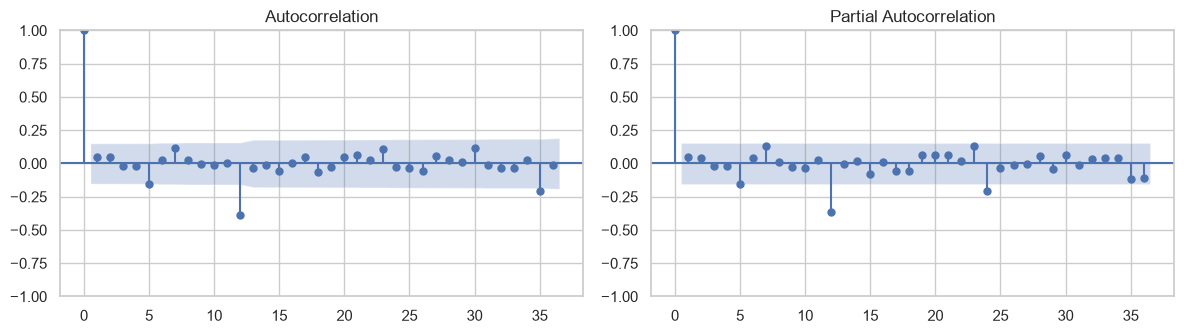

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
plot_acf(y.diff(12).dropna(), lags=36, ax=ax[0]); plot_pacf(y.diff(12).dropna(), lags=36, ax=ax[1], method="ywm")
plt.tight_layout(); plt.show()

## Exogenous regressors

In [4]:
X = pd.DataFrame(index=y.index)
X["shutdown"] = 0.0
# Share of the month the government was shut down (DOT was unfunded in all three).
X.loc["2013-10-01", "shutdown"] = 16 / 31
X.loc["2018-12-01", "shutdown"] = 10 / 31
X.loc["2019-01-01", "shutdown"] = 25 / 31
X.loc["2025-10-01", "shutdown"] = 1.0
X.loc["2025-11-01", "shutdown"] = 12 / 30
X["iija"] = (X.index >= "2021-11-01").astype(float)
X[X["shutdown"] > 0]

,shutdown,iija
month,,
2013-10-01,0.516129,0.0
2018-12-01,0.322581,0.0
2019-01-01,0.806452,0.0
2025-10-01,1.000000,1.0
2025-11-01,0.400000,1.0


## Order selection

Small grid over (p, q) × (P, Q) with d = 0, D = 1, fit on data through FY2021 so the backtest years stay
untouched. Ranked by AIC.

In [5]:
fit_end = "2021-09-01"
grid = []
for p, q, P, Q in itertools.product([0, 1, 2], [0, 1, 2], [0, 1], [0, 1]):
    try:
        r = SARIMAX(y[:fit_end], exog=X[:fit_end], order=(p, 0, q), seasonal_order=(P, 1, Q, 12), trend="c").fit(disp=0)
        grid.append({"order": (p, 0, q), "seasonal": (P, 1, Q, 12), "aic": r.aic, "bic": r.bic})
    except Exception:
        pass
grid = pd.DataFrame(grid).sort_values("aic")
grid.head(8).round(1)

,order,seasonal,aic,bic
1,"(0, 0, 0)","(0, 1, 1, 12)",54.9,68.3
3,"(0, 0, 0)","(1, 1, 1, 12)",55.0,71.1
29,"(2, 0, 1)","(0, 1, 1, 12)",55.1,76.5
31,"(2, 0, 1)","(1, 1, 1, 12)",55.5,79.6
5,"(0, 0, 1)","(0, 1, 1, 12)",55.9,72.0
13,"(1, 0, 0)","(0, 1, 1, 12)",56.0,72.0
7,"(0, 0, 1)","(1, 1, 1, 12)",56.1,74.9
15,"(1, 0, 0)","(1, 1, 1, 12)",56.2,75.0


In [6]:
best_order, best_seasonal = grid.iloc[0]["order"], grid.iloc[0]["seasonal"]
sarimax = SARIMAX(y, exog=X, order=best_order, seasonal_order=best_seasonal, trend="c").fit(disp=0)
print(sarimax.summary().tables[1])
for name in ["shutdown", "iija"]:
    b, (lo, hi) = sarimax.params[name], sarimax.conf_int().loc[name]
    print(f"{name}: ×{np.exp(b):.2f} on obligations (95% CI ×{np.exp(lo):.2f}-×{np.exp(hi):.2f})")

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.0303      0.009      3.393      0.001       0.013       0.048
shutdown      -0.9998      0.188     -5.330      0.000      -1.367      -0.632
iija           0.1665      0.086      1.927      0.054      -0.003       0.336
ma.S.L12      -0.8631      0.098     -8.843      0.000      -1.054      -0.672
sigma2         0.0824      0.009      9.444      0.000       0.065       0.100
shutdown: ×0.37 on obligations (95% CI ×0.25-×0.53)
iija: ×1.18 on obligations (95% CI ×1.00-×1.40)


## Residual diagnostics

Residuals should look like white noise: no autocorrelation left (Ljung-Box), roughly normal, with constant
variance.

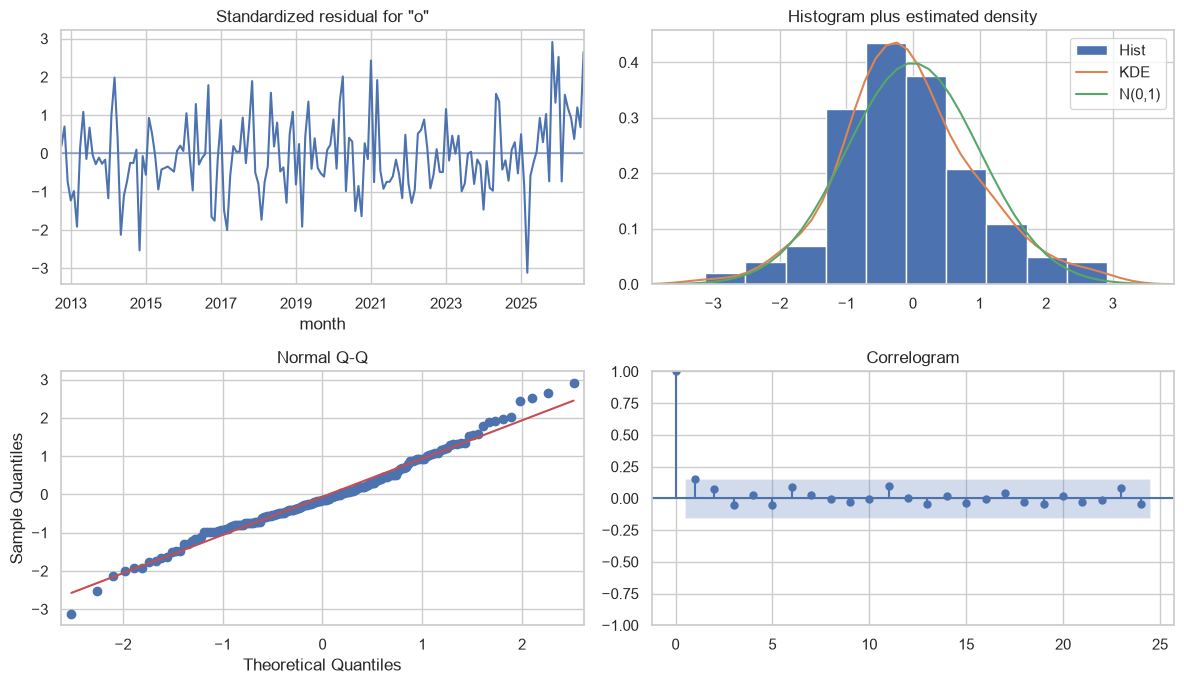

,lb_stat,lb_pvalue
6,7.471,0.188
12,9.429,0.582
24,13.288,0.945


In [7]:
fig = sarimax.plot_diagnostics(figsize=(12, 7), lags=24)
plt.tight_layout(); plt.savefig(FIG + "06_residual_diagnostics.png", dpi=120); plt.show()
acorr_ljungbox(sarimax.resid[13:], lags=[6, 12, 24], model_df=best_order[0] + best_order[2] + best_seasonal[0] + best_seasonal[2]).round(3)

## Rolling-origin backtest

Origins at the end of FY2021, 2022, 2023, 2024 and 2025. At each origin, refit on all data so far and forecast
the next 12 months. This mimics a budget office producing a forecast for the coming fiscal year.

Competing models:
- **Seasonal naive:** next year's month = this year's same month.
- **SARIMA:** best order, no regressors.
- **SARIMAX:** best order + shutdown and IIJA regressors. Shutdown values for the forecast year are taken as
  known. This is an *ex-post* evaluation, which is standard for intervention variables but flatters the model
  in the FY2026 window.

Metrics are on the dollar scale: MAPE, and the annual total error, which is what a planner cares about.

In [8]:
def backtest(origin):
    tr, te = slice(None, origin), slice(pd.Timestamp(origin) + pd.offsets.MonthBegin(1), None)
    y_tr, y_te = y[tr], y[te][:12]
    X_tr, X_te = X[tr], X[te][:12]
    out = {"seasonal naive": y_tr[-12:].values}
    sar = SARIMAX(y_tr, order=best_order, seasonal_order=best_seasonal, trend="c").fit(disp=0)
    out["SARIMA"] = sar.forecast(12).values
    sax = SARIMAX(y_tr, exog=X_tr, order=best_order, seasonal_order=best_seasonal, trend="c").fit(disp=0)
    out["SARIMAX"] = sax.forecast(12, exog=X_te).values
    rows = []
    actual = np.exp(y_te.values)
    for name, f in out.items():
        pred = np.exp(f)
        rows.append({"origin FY end": origin[:4], "model": name,
                     "MAPE": np.mean(np.abs(pred - actual) / actual),
                     "annual total error": pred.sum() / actual.sum() - 1})
    return rows, y_te, out

all_rows, paths = [], {}
for origin in ["2021-09-01", "2022-09-01", "2023-09-01", "2024-09-01", "2025-09-01"]:
    rows, y_te, out = backtest(origin)
    all_rows += rows; paths[origin] = (y_te, out)
bt = pd.DataFrame(all_rows)
display(bt.pivot(index="origin FY end", columns="model", values="MAPE").round(3))
display(bt.pivot(index="origin FY end", columns="model", values="annual total error").round(3))
bt.groupby("model")[["MAPE"]].mean().assign(
    abs_annual_error=bt.assign(a=bt["annual total error"].abs()).groupby("model")["a"].mean()).round(3)

model,SARIMA,SARIMAX,seasonal naive
origin FY end,,,
2021,0.189,0.186,0.348
2022,0.165,0.128,0.259
2023,0.144,0.182,0.267
2024,0.252,0.243,0.312
2025,0.501,0.342,0.483


model,SARIMA,SARIMAX,seasonal naive
origin FY end,,,
2021,-0.146,-0.130,-0.094
2022,-0.161,-0.070,-0.082
2023,-0.073,-0.002,0.019
2024,-0.087,-0.053,-0.061
2025,-0.362,-0.378,-0.334


,MAPE,abs_annual_error
model,,
SARIMA,0.250,0.166
SARIMAX,0.216,0.127
seasonal naive,0.334,0.118


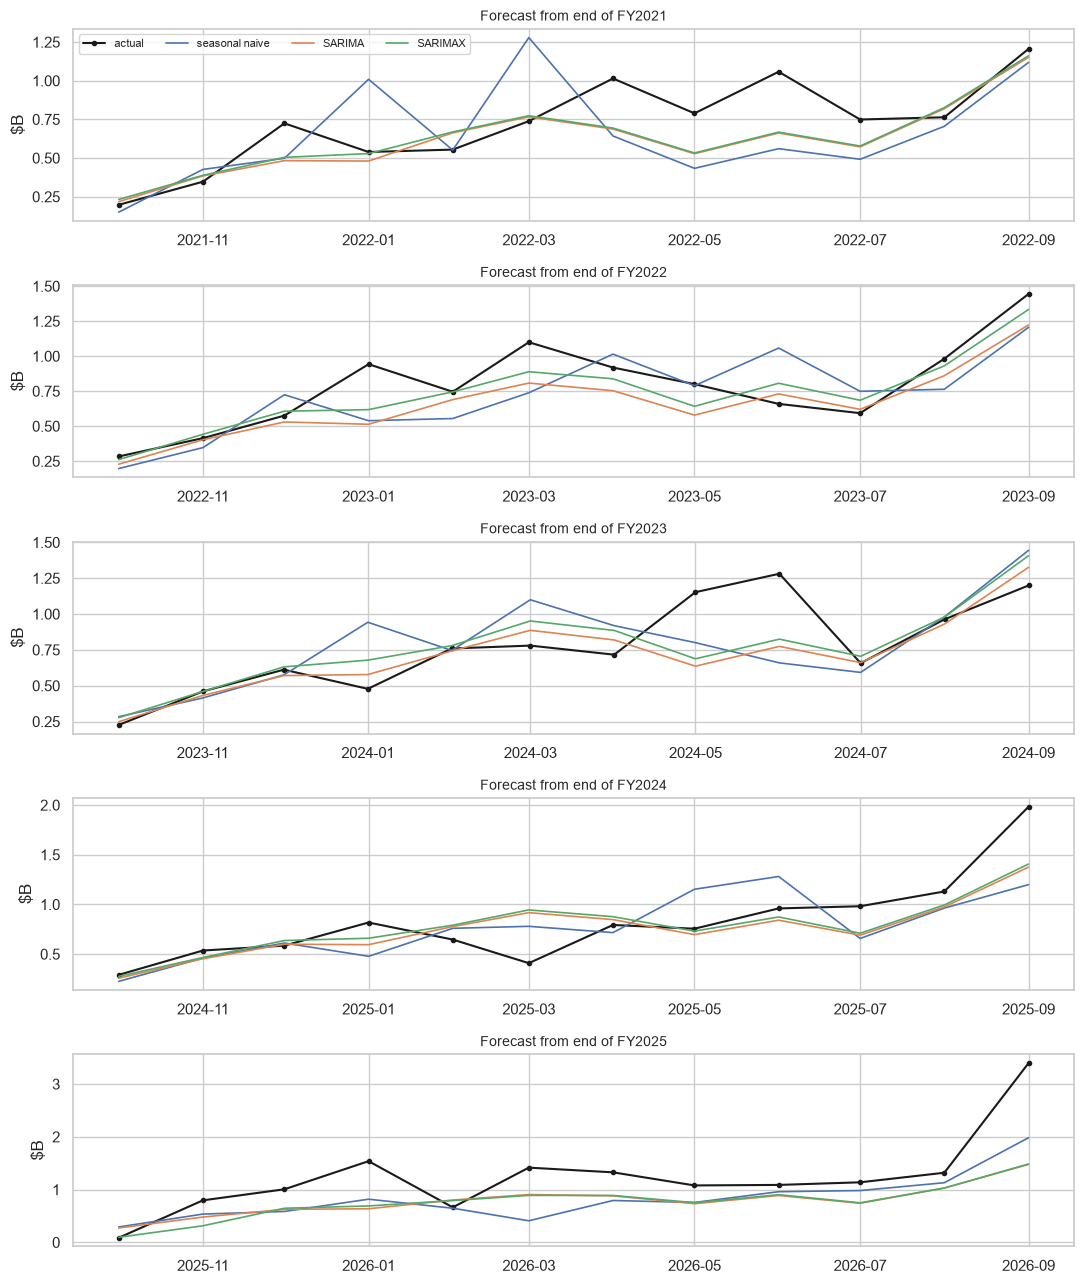

In [9]:
fig, axes = plt.subplots(len(paths), 1, figsize=(11, 2.6 * len(paths)), sharex=False)
for ax, (origin, (y_te, out)) in zip(axes, paths.items()):
    ax.plot(y_te.index, np.exp(y_te) / 1e9, "k-o", ms=3, label="actual")
    for name, f in out.items():
        ax.plot(y_te.index, np.exp(f) / 1e9, lw=1.2, label=name)
    ax.set_title(f"Forecast from end of FY{origin[:4]}", fontsize=10); ax.set_ylabel("$B")
axes[0].legend(ncol=4, fontsize=8)
plt.tight_layout(); plt.savefig(FIG + "06_backtest.png", dpi=120); plt.show()

## FY2027 forecast

Refit on everything. Assumptions for the regressors: no shutdown, and IIJA-era funding levels continue. IIJA
appropriations formally run through FY2026, so the second assumption is the main risk to this forecast.
The intervals are on the log scale, so they are asymmetric in dollars.

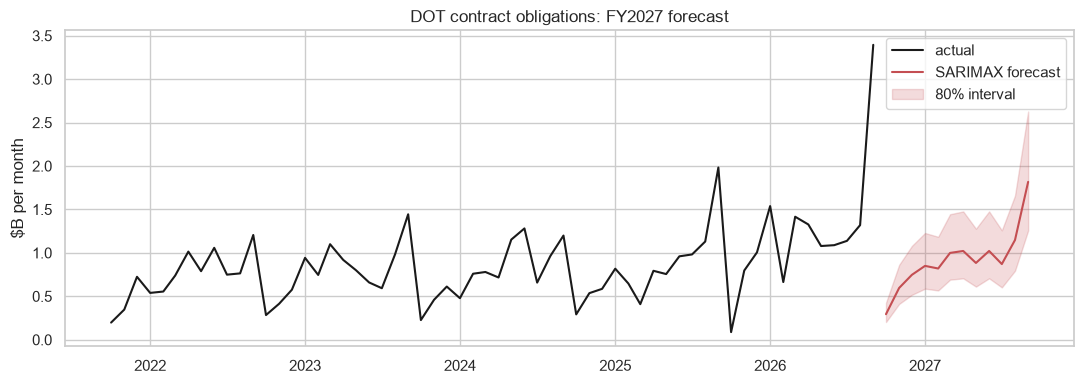

FY2027 point forecast: $11.1B (FY2026 actual: $14.9B)


In [10]:
future_idx = pd.date_range("2026-10-01", periods=12, freq="MS")
X_future = pd.DataFrame({"shutdown": 0.0, "iija": 1.0}, index=future_idx)
fc = sarimax.get_forecast(12, exog=X_future)
mean, ci = np.exp(fc.predicted_mean), np.exp(fc.conf_int(alpha=0.2))

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(y["2021-10-01":].index, np.exp(y["2021-10-01":]) / 1e9, "k", label="actual")
ax.plot(mean.index, mean / 1e9, "C3", label="SARIMAX forecast")
ax.fill_between(mean.index, ci.iloc[:, 0] / 1e9, ci.iloc[:, 1] / 1e9, color="C3", alpha=0.2, label="80% interval")
ax.set(title="DOT contract obligations: FY2027 forecast", ylabel="$B per month"); ax.legend()
plt.tight_layout(); plt.savefig(FIG + "06_fy27_forecast.png", dpi=120); plt.show()
print(f"FY2027 point forecast: ${mean.sum() / 1e9:.1f}B (FY2026 actual: ${np.exp(y['2025-10-01':]).sum() / 1e9:.1f}B)")

In [11]:
# What drove the FY2026 jump? Obligations by sub-agency and the largest recipients.
fy26 = pd.read_parquet("../data/raw/dot_contracts_fy2026.parquet",
                       columns=["recipient_name", "awarding_sub_agency_name", "federal_action_obligation"])
fy26["federal_action_obligation"] = pd.to_numeric(fy26["federal_action_obligation"])
display((fy26.groupby("awarding_sub_agency_name")["federal_action_obligation"].sum().nlargest(4) / 1e9).round(2))
display((fy26.groupby("recipient_name")["federal_action_obligation"].sum().nlargest(8) / 1e9).round(2))

awarding_sub_agency_name
Federal Aviation Administration                   10.60
Maritime Administration                            1.86
Federal Highway Administration                     1.35
National Highway Traffic Safety Administration     0.30
Name: federal_action_obligation, dtype: float64

recipient_name
HARRIS CORPORATION                                1.17
TOTE SERVICES, LLC                                0.78
RAYTHEON COMPANY                                  0.74
LEIDOS, INC.                                      0.68
ROHDE & SCHWARZ USA, INC.                         0.65
FREQUENTIS USA, INC                               0.63
SCIENCE APPLICATIONS INTERNATIONAL CORPORATION    0.46
CROWLEY GOVERNMENT SERVICES, INC.                 0.40
Name: federal_action_obligation, dtype: float64

## Findings

- **The airline-style model wins on AIC.** A seasonal MA(1) on the seasonally differenced log series, with
  drift (SARIMA(0,0,0)(0,1,1)₁₂), beat every richer ARMA order. ADF and KPSS agree that one seasonal difference
  is enough, and the Ljung-Box tests show no autocorrelation left in the residuals.
- **Shutdowns cut a month's obligations by about 63%** (×0.37 per fully shut month, 95% CI ×0.25-×0.53). The
  **IIJA step** is estimated at +18%, borderline significant (p ≈ 0.05).
- **SARIMAX gives the best month-by-month accuracy** in the backtest (MAPE 0.22 vs 0.25 for SARIMA and 0.33 for
  seasonal naive). For **annual totals**, the simple seasonal naive is just as good. Every model under-forecast
  most years, because DOT spending has trended up faster than the drift term allows.
- **FY2026 broke the pattern:** obligations reached ~$14.9B against ~$9.9B the year before, and every model
  missed by about 35%. The jump is concentrated in FAA air traffic control equipment vendors (radar, radio and
  voice-switch suppliers), consistent with the air traffic control modernization funding appropriated in 2025.
  That is a structural change no univariate model could anticipate. The FY2027 forecast (~$11B) treats most of
  FY2026 as a one-off. If the modernization money keeps flowing, it will be too low, and an explicit regressor
  for it would be the next step once a few more months of data exist.